In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual para gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

# Ruta relativa al dataset maestro procesado
RUTA_DATASET = Path("../datasets/processed/dataset_maestro_permanencia.parquet")

df_raw = pd.read_parquet(RUTA_DATASET)
print(f"Dataset maestro cargado exitosamente: {df_raw.shape[0]:,} filas y {df_raw.shape[1]} columnas.")

Dataset maestro cargado exitosamente: 1,063,954 filas y 26 columnas.


In [9]:
# Diagnóstico de pérdida de observaciones al filtrar NEM < 400 o nulo
df_diagnostico = df_raw.copy()

# Definir condición de sin NEM válido
cond_sin_nem = (df_diagnostico["NEM"] < 400) | (df_diagnostico["NEM"].isna())

# Tabla comparativa por grupo nacional
resumen_perdida = df_diagnostico.groupby("NACIONALIDAD").agg(
    total_estudiantes=("MRUN", "count"),
    sin_nem_valido=("NEM", lambda s: ((s < 400) | s.isna()).sum()),
    pct_perdida=("NEM", lambda s: (((s < 400) | s.isna()).mean() * 100).round(2)),
    permanencia_con_nem=("PERMANECE_SISTEMA", lambda s: s[~cond_sin_nem].mean() * 100),
    permanencia_sin_nem=("PERMANECE_SISTEMA", lambda s: s[cond_sin_nem].mean() * 100)
).reset_index()

display(resumen_perdida)
print(f"\nTotal registros eliminados a nivel global: {cond_sin_nem.sum():,} ({cond_sin_nem.mean()*100:.2f}%)")

,NACIONALIDAD,total_estudiantes,sin_nem_valido,pct_perdida,permanencia_con_nem,permanencia_sin_nem
0,0,1026889,1146,0.11,85.983136,79.057592
1,1,27072,49,0.18,84.354069,77.551020
2,2,9993,30,0.30,79.845428,83.333333



Total registros eliminados a nivel global: 1,225 (0.12%)


In [10]:
# ============================================================
# 1. LIMPIEZA DE CASOS COMPLETOS (EXCLUSIÓN DE CASOS INVÁLIDOS)
# ============================================================
df_estudiantes = df_raw.copy()

# A. Descartar registros sin NEM válido (NEM < 400 o NaN) y sin decil o dependencia
# Esto solo descarta el ~0.12% de la base total y el 0.18% de extranjeros
filtro_valido = (
    df_estudiantes["NEM"].between(400, 700) &
    df_estudiantes["DECIL_SE4"].between(1, 10) &
    df_estudiantes["COD_DEPE"].notna()
)
df_estudiantes = df_estudiantes[filtro_valido].copy()

# B. Corrección del Arancel en UF a Pesos chilenos según año de cohorte
uf_anual = {2022: 33100, 2023: 35800, 2024: 37200, 2025: 38400}
es_uf = df_estudiantes["FORMATO_VALORES"].astype(str).str.upper().str.contains("UF")
factor_uf = df_estudiantes["ANIO_COHORTE"].map(uf_anual)
df_estudiantes.loc[es_uf, "VALOR_ARANCEL"] = df_estudiantes.loc[es_uf, "VALOR_ARANCEL"] * factor_uf[es_uf]

# C. Corrección de edades administrativas anómalas (< 16 o > 70 por defecto 190001)
edad_invalida = (df_estudiantes["EDAD"] < 16) | (df_estudiantes["EDAD"] > 70)
df_estudiantes.loc[edad_invalida, "EDAD"] = np.nan
df_estudiantes["EDAD"] = df_estudiantes["EDAD"].fillna(
    df_estudiantes.groupby("JORNADA")["EDAD"].transform("median")
)

# D. Dependencia escolar agrupada en 3 categorías reales (Glosario FUAS)
mapa_dependencia = {
    1.0: "Publico_Municipal",
    2.0: "Publico_Municipal",
    6.0: "Publico_Municipal",
    3.0: "Particular_Subvencionado",
    5.0: "Particular_Subvencionado",
    4.0: "Particular_Pagado"
}
df_estudiantes["DEPENDENCIA_COLEGIO"] = df_estudiantes["COD_DEPE"].map(mapa_dependencia)

print(f"Estudiantes totales con datos completos: {len(df_estudiantes):,}")
print("Extranjeros retenidos:", (df_estudiantes["NACIONALIDAD"] == 1).sum())

Estudiantes totales con datos completos: 1,060,791
Extranjeros retenidos: 26991


In [11]:
# ============================================================
# 2. DEFINICIÓN FINAL DE LA MATRIZ X_CLUSTER (10 VARIABLES)
# ============================================================

cols_numericas = [
    "NEM",
    "EDAD",
    "DECIL_SE4",
    "VALOR_ARANCEL",
    "ACRE_INST_ANIO"
]

cols_categoricas = [
    "GEN_ALU",
    "DEPENDENCIA_COLEGIO",
    "TIPO_INST_3",
    "JORNADA",
    "AREA_CONOCIMIENTO"
]

# Matriz limpia lista para escalamiento y codificación
X_cluster = df_estudiantes[cols_numericas + cols_categoricas].copy()

print("Dimensiones finales de X_cluster:", X_cluster.shape)
print("Valores nulos en X_cluster:", X_cluster.isna().sum().sum())
display(X_cluster.head())

Dimensiones finales de X_cluster: (1060791, 10)
Valores nulos en X_cluster: 0


,NEM,EDAD,DECIL_SE4,VALOR_ARANCEL,ACRE_INST_ANIO,GEN_ALU,DEPENDENCIA_COLEGIO,TIPO_INST_3,JORNADA,AREA_CONOCIMIENTO
0,595.0,19.0,9.0,7679200.0,6.0,2,Particular_Subvencionado,Universidades Privadas,Diurna,Derecho
1,560.0,39.0,5.0,2470000.0,5.0,2,Publico_Municipal,Institutos Profesionales,Vespertina,Salud
2,685.0,18.0,9.0,5713000.0,0.0,2,Particular_Pagado,Universidades Estatales CRUCH,Diurna,Salud
3,647.0,18.0,9.0,4251000.0,7.0,2,Particular_Pagado,Universidades Estatales CRUCH,Diurna,Salud
4,530.0,24.0,8.0,2250000.0,7.0,1,Publico_Municipal,Centros de Formación Técnica Privados,Diurna,Tecnología


In [14]:
# Comprobación de que no quedan nulos en la matriz de clustering
nulos_restantes = X_cluster.isna().sum()
print("Nulos por columna en X_cluster:\n", nulos_restantes[nulos_restantes > 0])
if nulos_restantes.sum() == 0:
    print(">> Integridad confirmada: 0 nulos en toda la matriz X_cluster.")

display(X_cluster.head())

Nulos por columna en X_cluster:
 Series([], dtype: int64)
>> Integridad confirmada: 0 nulos en toda la matriz X_cluster.


,NEM,EDAD,DECIL_SE4,VALOR_ARANCEL,ACRE_INST_ANIO,GEN_ALU,DEPENDENCIA_COLEGIO,TIPO_INST_3,JORNADA,AREA_CONOCIMIENTO
0,595.0,19.0,9.0,7679200.0,6.0,2,Particular_Subvencionado,Universidades Privadas,Diurna,Derecho
1,560.0,39.0,5.0,2470000.0,5.0,2,Publico_Municipal,Institutos Profesionales,Vespertina,Salud
2,685.0,18.0,9.0,5713000.0,0.0,2,Particular_Pagado,Universidades Estatales CRUCH,Diurna,Salud
3,647.0,18.0,9.0,4251000.0,7.0,2,Particular_Pagado,Universidades Estatales CRUCH,Diurna,Salud
4,530.0,24.0,8.0,2250000.0,7.0,1,Publico_Municipal,Centros de Formación Técnica Privados,Diurna,Tecnología


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA

# 1. Pipeline de transformación
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), cols_numericas),
        ("cat", OneHotEncoder(drop="first", sparse_output=False), cols_categoricas)
    ]
)

print("Ajustando preprocesador...")
X_prep = preprocessor.fit_transform(X_cluster)
print(f"Matriz con One-Hot Encoding: {X_prep.shape[0]:,} filas × {X_prep.shape[1]} columnas.")

# 2. Análisis de Componentes Principales (PCA) conservando el 85% de varianza
pca = PCA(n_components=0.85, random_state=42)
X_pca = pca.fit_transform(X_prep)

var_acumulada = pca.explained_variance_ratio_.sum() * 100
n_comp = X_pca.shape[1]
print(f"PCA completado: {n_comp} componentes explican el {var_acumulada:.2f}% de la varianza total.")

Ajustando preprocesador...
Matriz con One-Hot Encoding: 1,060,791 filas × 26 columnas.
PCA completado: 9 componentes explican el 87.61% de la varianza total.


Evaluando K = 2 hasta 8 en submuestra de 25.000 estudiantes...
K = 2 | Inercia: 130096.3 | Silhouette Score: 0.1947
K = 3 | Inercia: 111543.7 | Silhouette Score: 0.1853
K = 4 | Inercia: 103581.5 | Silhouette Score: 0.1619
K = 5 | Inercia: 95446.8 | Silhouette Score: 0.1637
K = 6 | Inercia: 90067.8 | Silhouette Score: 0.1472
K = 7 | Inercia: 82952.8 | Silhouette Score: 0.1527
K = 8 | Inercia: 80014.4 | Silhouette Score: 0.1421


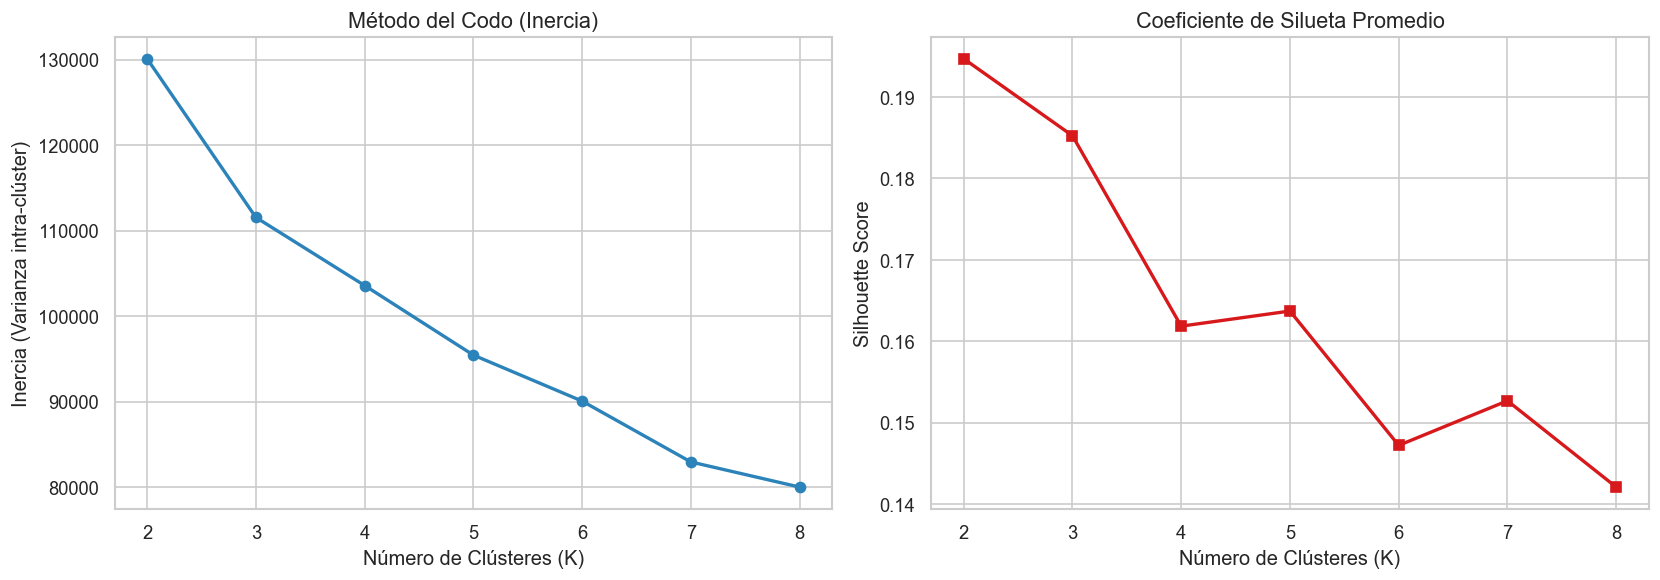

In [ ]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

# Submuestra representativa para silueta y codo
np.random.seed(42)
idx_sample = np.random.choice(X_pca.shape[0], size=25000, replace=False)
X_sample = X_pca[idx_sample]

k_range = range(2, 9)
inercias = []
silhouettes = []

print("Evaluando K = 2 hasta 8 en submuestra de 25.000 estudiantes...")
for k in k_range:
    # MiniBatchKMeans entrena por lotes, ideal para grandes volúmenes
    mbk = MiniBatchKMeans(n_clusters=k, batch_size=2048, random_state=42, n_init=3)
    labels = mbk.fit_predict(X_sample)
    
    inercias.append(mbk.inertia_)
    sil = silhouette_score(X_sample, labels)
    silhouettes.append(sil)
    print(f"K = {k} | Inercia: {mbk.inertia_:.1f} | Silhouette Score: {sil:.4f}")

# Gráficos diagnósticos de selección de K
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Curva del Codo
axes[0].plot(k_range, inercias, marker="o", color="#2b83ba", lw=2)
axes[0].set_title("Método del Codo (Inercia)", fontsize=13)
axes[0].set_xlabel("Número de Clústeres (K)")
axes[0].set_ylabel("Inercia (Varianza intra-clúster)")

# Coeficiente de Silueta
axes[1].plot(k_range, silhouettes, marker="s", color="#d7191c", lw=2)
axes[1].set_title("Coeficiente de Silueta Promedio", fontsize=13)
axes[1].set_xlabel("Número de Clústeres (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [17]:
# SELECCIONAR K (Ajusta este número según el codo y silueta obtenidos, ej. 4)
K_ELEGIDO = 3

print(f"Entrenando MiniBatchKMeans definitivo con K = {K_ELEGIDO} sobre todo el dataset...")
modelo_clustering = MiniBatchKMeans(n_clusters=K_ELEGIDO, batch_size=4096, random_state=42, n_init=5)
df_estudiantes["CLUSTER_ID"] = modelo_clustering.fit_predict(X_pca)

# Caracterización sociológica de cada arquetipo en variables numéricas originales
perfil_num = df_estudiantes.groupby("CLUSTER_ID")[cols_numericas].agg(["median", "mean"]).round(1)
display(perfil_num)

# Distribución institucional y sociodemográfica por arquetipo
for col in ["TIPO_INST_3", "JORNADA", "DEPENDENCIA_COLEGIO"]:
    print(f"\n--- Distribución de {col} por Clúster (%) ---")
    tabla_cat = pd.crosstab(df_estudiantes["CLUSTER_ID"], df_estudiantes[col], normalize="index") * 100
    display(tabla_cat.round(1))

Entrenando MiniBatchKMeans definitivo con K = 3 sobre todo el dataset...


NEM          EDAD       DECIL_SE4      VALOR_ARANCEL             \
           median   mean median  mean    median mean        median       mean   
CLUSTER_ID                                                                      
0           560.0  559.5   20.0  20.6       4.0  4.7     2600000.0  2671053.3   
1           630.0  624.9   19.0  19.0       5.0  5.7     5221000.0  5363347.8   
2           542.0  544.6   33.0  33.7       5.0  5.6     2070000.0  2224004.9   

           ACRE_INST_ANIO       
                   median mean  
CLUSTER_ID                      
0                     6.0  5.8  
1                     5.0  5.5  
2                     5.0  4.1


--- Distribución de TIPO_INST_3 por Clúster (%) ---


TIPO_INST_3,Centros de Formación Técnica Estatales,Centros de Formación Técnica Privados,Institutos Profesionales,Universidades Estatales CRUCH,Universidades Privadas,Universidades Privadas CRUCH
CLUSTER_ID,,,,,,
0,0.0,31.0,51.4,7.6,5.0,5.0
1,0.0,0.7,1.7,26.5,42.4,28.7
2,12.2,20.9,54.5,3.3,7.6,1.5



--- Distribución de JORNADA por Clúster (%) ---


JORNADA,A Distancia,Diurna,Otra,Semipresencial,Vespertina
CLUSTER_ID,,,,,
0,2.1,76.5,0.0,0.2,21.2
1,0.1,98.8,0.0,0.2,0.9
2,21.2,23.5,0.1,1.8,53.4



--- Distribución de DEPENDENCIA_COLEGIO por Clúster (%) ---


DEPENDENCIA_COLEGIO,Particular_Pagado,Particular_Subvencionado,Publico_Municipal
CLUSTER_ID,,,
0,1.9,48.8,49.3
1,11.5,59.3,29.2
2,2.4,33.6,64.0


In [18]:
# Tasa de permanencia de chilenos vs extranjeros dentro de cada arquetipo
df_analisis = df_estudiantes[df_estudiantes["NACIONALIDAD"].isin([0, 1])].copy()
df_analisis["GRUPO_NAC"] = df_analisis["NACIONALIDAD"].map({0: "Chileno", 1: "Extranjero"})

resumen_arquetipos = df_analisis.groupby(["CLUSTER_ID", "GRUPO_NAC"]).agg(
    total=("PERMANECE_SISTEMA", "count"),
    permanencia_pct=("PERMANECE_SISTEMA", lambda s: (s.mean() * 100).round(2))
).unstack()

display(resumen_arquetipos)

total            permanencia_pct           
GRUPO_NAC  Chileno Extranjero         Chileno Extranjero
CLUSTER_ID                                              
0           448920      11340           83.30      82.25
1           381096       8725           94.50      92.68
2           193833       6926           75.44      77.39

In [19]:
# SELECCIONAR K (Ajusta este número según el codo y silueta obtenidos, ej. 4)
K_ELEGIDO = 5

print(f"Entrenando MiniBatchKMeans definitivo con K = {K_ELEGIDO} sobre todo el dataset...")
modelo_clustering = MiniBatchKMeans(n_clusters=K_ELEGIDO, batch_size=4096, random_state=42, n_init=5)
df_estudiantes["CLUSTER_ID"] = modelo_clustering.fit_predict(X_pca)

# Caracterización sociológica de cada arquetipo en variables numéricas originales
perfil_num = df_estudiantes.groupby("CLUSTER_ID")[cols_numericas].agg(["median", "mean"]).round(1)
display(perfil_num)

# Distribución institucional y sociodemográfica por arquetipo
for col in ["TIPO_INST_3", "JORNADA", "DEPENDENCIA_COLEGIO"]:
    print(f"\n--- Distribución de {col} por Clúster (%) ---")
    tabla_cat = pd.crosstab(df_estudiantes["CLUSTER_ID"], df_estudiantes[col], normalize="index") * 100
    display(tabla_cat.round(1))

Entrenando MiniBatchKMeans definitivo con K = 5 sobre todo el dataset...


NEM          EDAD       DECIL_SE4      VALOR_ARANCEL             \
           median   mean median  mean    median mean        median       mean   
CLUSTER_ID                                                                      
0           547.0  547.0   26.0  26.4       6.0  6.3     1966251.0  2134543.6   
1           626.0  623.1   19.0  19.0       4.0  4.1     5000000.0  5122744.7   
2           622.0  618.0   19.0  19.3       9.0  8.8     5060000.0  5174650.5   
3           555.0  556.4   20.0  20.5       4.0  4.4     2566000.0  2618026.5   
4           540.0  544.0   36.0  37.8       4.0  5.1     2250000.0  2384734.5   

           ACRE_INST_ANIO       
                   median mean  
CLUSTER_ID                      
0                     4.0  3.0  
1                     5.0  5.4  
2                     6.0  5.8  
3                     6.0  5.9  
4                     5.0  5.3


--- Distribución de TIPO_INST_3 por Clúster (%) ---


TIPO_INST_3,Centros de Formación Técnica Estatales,Centros de Formación Técnica Privados,Institutos Profesionales,Universidades Estatales CRUCH,Universidades Privadas,Universidades Privadas CRUCH
CLUSTER_ID,,,,,,
0,21.2,7.4,54.5,4.7,11.8,0.4
1,0.0,1.3,2.4,28.2,39.8,28.3
2,0.0,4.7,10.9,21.2,38.3,24.9
3,0.0,33.6,52.8,6.0,3.4,4.3
4,0.6,32.8,55.6,3.4,5.4,2.2



--- Distribución de JORNADA por Clúster (%) ---


JORNADA,A Distancia,Diurna,Otra,Semipresencial,Vespertina
CLUSTER_ID,,,,,
0,24.0,32.8,0.2,2.0,41.0
1,0.1,98.7,0.0,0.1,1.1
2,0.5,96.0,0.0,0.3,3.1
3,1.7,76.5,0.0,0.2,21.6
4,15.5,23.1,0.1,1.2,60.1



--- Distribución de DEPENDENCIA_COLEGIO por Clúster (%) ---


DEPENDENCIA_COLEGIO,Particular_Pagado,Particular_Subvencionado,Publico_Municipal
CLUSTER_ID,,,
0,2.8,39.1,58.1
1,3.9,60.9,35.2
2,25.1,55.1,19.8
3,1.5,48.0,50.5
4,2.2,31.6,66.1


In [20]:
# Tasa de permanencia de chilenos vs extranjeros dentro de cada arquetipo
df_analisis = df_estudiantes[df_estudiantes["NACIONALIDAD"].isin([0, 1])].copy()
df_analisis["GRUPO_NAC"] = df_analisis["NACIONALIDAD"].map({0: "Chileno", 1: "Extranjero"})

resumen_arquetipos = df_analisis.groupby(["CLUSTER_ID", "GRUPO_NAC"]).agg(
    total=("PERMANECE_SISTEMA", "count"),
    permanencia_pct=("PERMANECE_SISTEMA", lambda s: (s.mean() * 100).round(2))
).unstack()

display(resumen_arquetipos)

total            permanencia_pct           
GRUPO_NAC  Chileno Extranjero         Chileno Extranjero
CLUSTER_ID                                              
0           107765       3565           74.78      75.37
1           285578       7289           94.39      93.80
2           139529       2575           92.85      85.83
3           376100       9263           82.95      82.39
4           114877       4299           77.17      79.25